# Brain Tumor MRI Classification with Convolutional Neural Networks (CNNs)

* **Dataset:** Brain Tumor MRI Dataset *(Kaggle — Masoud Nickparvar)* — 7,200 images across 4 classes (`glioma`, `meningioma`, `notumor`, `pituitary`).
* **Objectives:**
  1. Preprocess images, create an independent stratified split (`Train / Validation / Test`), and perform Exploratory Data Analysis (EDA).
  2. Build and train a **Baseline CNN** to observe and quantify overfitting.
  3. Apply and compare regularization techniques (**Dropout, L2 Weight Decay, Data Augmentation, Early Stopping**).
  4. Perform quantitative evaluation (`Accuracy, Loss, Macro F1, Confusion Matrix`) and qualitative **Error Analysis**.
  5. **Transfer Learning Extension:** Fine-tune a pre-trained **ResNet18** backbone and benchmark all 5 configurations.

---
## Section 1: Data Preparation, Preprocessing & EDA
* Split the `Training` directory (5,600 images) into **80% Train (4,480 images) / 20% Validation (1,120 images)** using stratified sampling (`SEED = 42`).
* Keep the `Testing` directory (**1,600 images**) strictly isolated as an independent test set.
* Resize images to `128×128×3` RGB and normalize using ImageNet statistics to ensure consistency with Transfer Learning in Section 5.

In [1]:
import os
from collections import Counter
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

DATA_DIR = path
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR = os.path.join(DATA_DIR, "Testing")

def _to_rgb(img):
    return img.convert("RGB")

IMG_SIZE = 128
BATCH_SIZE = 32
SEED = 42

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.Lambda(_to_rgb),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])]
)

aug_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Lambda(_to_rgb),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

full_train_base = datasets.ImageFolder(TRAIN_DIR, transform=eval_transform)
targets = full_train_base.targets
indices = list(range(len(targets)))

train_idx, val_idx = train_test_split(
    indices,
    test_size = 0.2,
    stratify = targets,
    random_state=SEED
)

train_dataset = Subset(datasets.ImageFolder(TRAIN_DIR, transform=eval_transform), train_idx)
train_dataset_aug = Subset(datasets.ImageFolder(TRAIN_DIR, transform=aug_transform), train_idx)
val_dataset = Subset(datasets.ImageFolder(TRAIN_DIR, transform=eval_transform), val_idx)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

classes = full_train_base.classes
print("Classes:", classes)
print("Train size:", len(train_dataset), Counter([targets[i] for i in train_idx]))
print("Val size:  ", len(val_dataset),   Counter([targets[i] for i in val_idx]))
print("Test size: ", len(test_dataset),  Counter(test_dataset.targets))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train size: 4480 Counter({3: 1120, 2: 1120, 0: 1120, 1: 1120})
Val size:   1120 Counter({0: 280, 1: 280, 3: 280, 2: 280})
Test size:  1600 Counter({0: 400, 1: 400, 2: 400, 3: 400})


### 1.1. Class Distribution and Representative MRI Samples

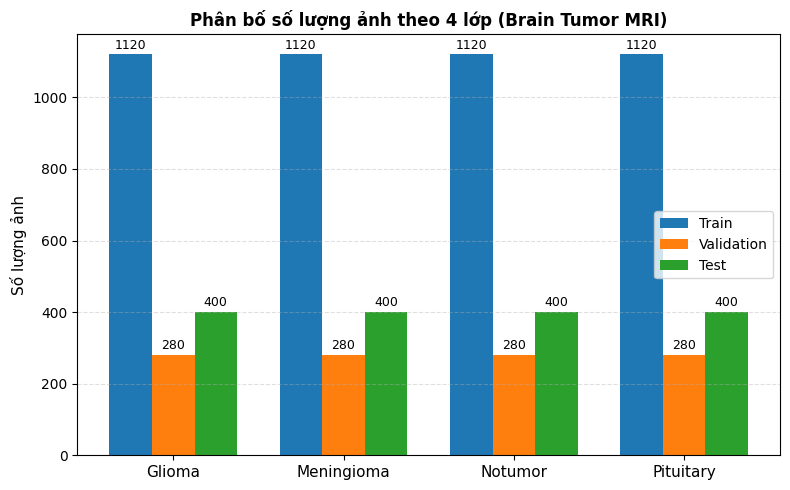

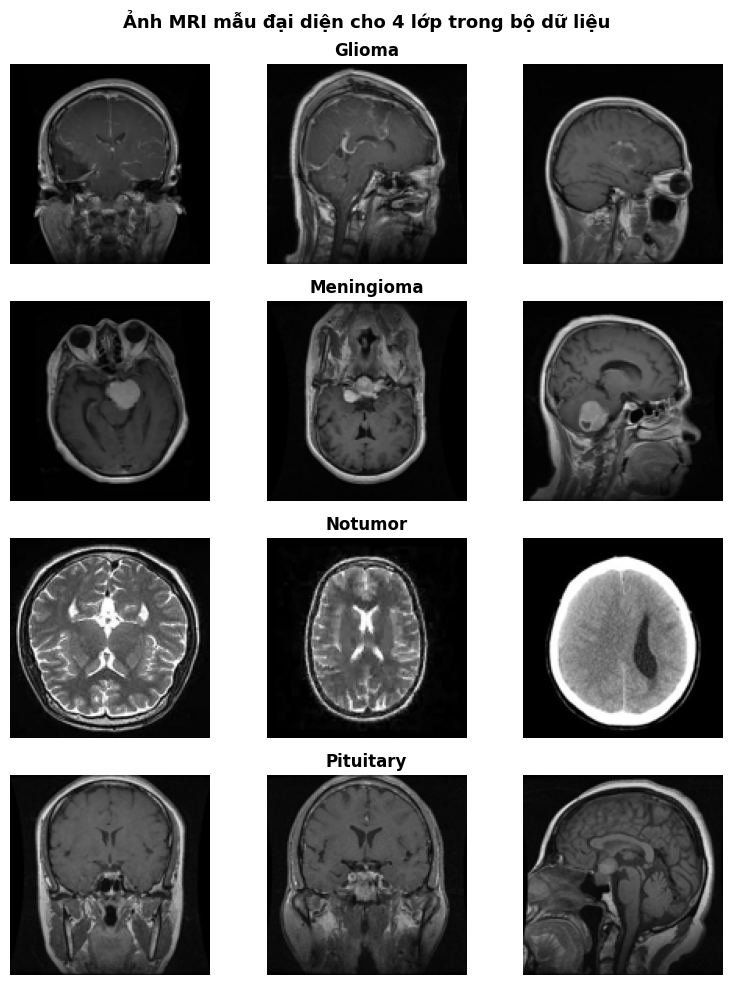

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

train_counts = Counter([targets[i] for i in train_idx])
val_counts   = Counter([targets[i] for i in val_idx])
test_counts  = Counter(test_dataset.targets)

x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
b1 = ax.bar(x - width, [train_counts[i] for i in range(len(classes))], width, label="Train")
b2 = ax.bar(x,         [val_counts[i]   for i in range(len(classes))], width, label="Validation")
b3 = ax.bar(x + width, [test_counts[i]  for i in range(len(classes))], width, label="Test")

for bars in [b1, b2, b3]:
    ax.bar_label(bars, padding=2, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels([c.capitalize() for c in classes], fontsize=11)
ax.set_ylabel("Number of Images", fontsize=11)
ax.set_title("Class Distribution Across Splits (Brain Tumor MRI)", fontsize=12, fontweight="bold")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("../figures/class_distribution.png", dpi=300)
plt.show()

raw_ds = datasets.ImageFolder(TRAIN_DIR)
fig, axes = plt.subplots(4, 3, figsize=(8, 10), facecolor="white")

for cls_idx, cls_name in enumerate(classes):
    cls_indices = [i for i, t in enumerate(raw_ds.targets) if t == cls_idx][:3]
    for col, img_idx in enumerate(cls_indices):
        img, _ = raw_ds[img_idx]
        axes[cls_idx, col].imshow(img.resize((128, 128)))
        axes[cls_idx, col].axis("off")
        if col == 1:
            axes[cls_idx, col].set_title(cls_name.capitalize(), fontsize=12, fontweight="bold")

plt.suptitle("Representative MRI Scans per Class", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../figures/dataset_samples.png", dpi=300)
plt.show()

---
## Section 2: Baseline CNN — Observing Overfitting
* 3-block architecture: `Conv2D (3×3) -> ReLU -> MaxPool2d (2×2)` (`32 -> 64 -> 128` filters) + `FC (256 -> 4)`.
* Trained **without** regularization (no Dropout, Weight Decay, or Data Augmentation) to establish a clear baseline.

In [3]:
import torch
from torch import nn

class BaselineCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(BaselineCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32768, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        y = self.fc2(x)
        return y

In [4]:
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BaselineCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

NUM_EPOCHS = 25
for epoch in range(NUM_EPOCHS):
  model.train()
  running_loss = 0.0
  running_correct = 0
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()
    running_loss += loss.item()*images.size(0)
    running_correct += (outputs.argmax(dim=1) == labels).sum().item()
  epoch_train_loss = running_loss/len(train_dataset)
  epoch_train_acc = running_correct/len(train_dataset)

  model.eval()
  val_running_loss = 0.0
  val_running_correct = 0
  with torch.no_grad():
      for images, labels in val_loader:
          images, labels = images.to(device), labels.to(device)
          outputs = model(images)
          loss = criterion(outputs, labels)
          val_running_loss += loss.item() * images.size(0)
          val_running_correct += (outputs.argmax(dim=1) == labels).sum().item()
  epoch_val_loss = val_running_loss / len(val_dataset)
  epoch_val_acc = val_running_correct / len(val_dataset)

  history["train_loss"].append(epoch_train_loss)
  history["train_acc"].append(epoch_train_acc)
  history["val_loss"].append(epoch_val_loss)
  history["val_acc"].append(epoch_val_acc)
  print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} || "
        f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")



Epoch [01/25] Train Loss: 0.8155 | Train Acc: 0.6741 || Val Loss: 0.5014 | Val Acc: 0.8161
Epoch [02/25] Train Loss: 0.4065 | Train Acc: 0.8478 || Val Loss: 0.4048 | Val Acc: 0.8527
Epoch [03/25] Train Loss: 0.2627 | Train Acc: 0.9025 || Val Loss: 0.2768 | Val Acc: 0.9036
Epoch [04/25] Train Loss: 0.1550 | Train Acc: 0.9433 || Val Loss: 0.2704 | Val Acc: 0.9205
Epoch [05/25] Train Loss: 0.1115 | Train Acc: 0.9627 || Val Loss: 0.3105 | Val Acc: 0.9223
Epoch [06/25] Train Loss: 0.0634 | Train Acc: 0.9761 || Val Loss: 0.3464 | Val Acc: 0.9268
Epoch [07/25] Train Loss: 0.0474 | Train Acc: 0.9821 || Val Loss: 0.3171 | Val Acc: 0.9366
Epoch [08/25] Train Loss: 0.0264 | Train Acc: 0.9917 || Val Loss: 0.3292 | Val Acc: 0.9295
Epoch [09/25] Train Loss: 0.0297 | Train Acc: 0.9908 || Val Loss: 0.3305 | Val Acc: 0.9357
Epoch [10/25] Train Loss: 0.0143 | Train Acc: 0.9958 || Val Loss: 0.3489 | Val Acc: 0.9339
Epoch [11/25] Train Loss: 0.0092 | Train Acc: 0.9975 || Val Loss: 0.4098 | Val Acc: 0.9339

### 2.1. Evaluation Helper and Baseline Test Results

In [5]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import numpy as np

def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    y_true, y_pred, y_probs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()*images.size(0)
            probs = torch.softmax(outputs, dim = 1)
            preds = outputs.argmax(dim = 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_probs.extend(probs.cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_probs = np.array(y_probs)
    avg_loss = running_loss / len(loader.dataset)
    acc = (y_pred == y_true).mean()
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    return avg_loss, acc, macro_f1, y_true, y_pred, y_probs

In [6]:
test_loss, test_acc, test_f1, y_true_base, y_pred_base, y_probs_base = evaluate_model(
    model, test_loader, criterion, device
)
print(f"Baseline Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.4f} | Macro F1: {test_f1:.4f}\n")
print(classification_report(y_true_base, y_pred_base, target_names=classes, digits=4))

Baseline Test Loss: 2.7006 | Test Acc: 0.8981 | Macro F1: 0.8965

              precision    recall  f1-score   support

      glioma     0.9364    0.7725    0.8466       400
  meningioma     0.8495    0.8750    0.8621       400
     notumor     0.8764    0.9925    0.9308       400
   pituitary     0.9407    0.9525    0.9466       400

    accuracy                         0.8981      1600
   macro avg     0.9007    0.8981    0.8965      1600
weighted avg     0.9007    0.8981    0.8965      1600



In [7]:
history_base = history
results = {
    "Baseline": {
        "test_loss": test_loss, "test_acc": test_acc, "test_f1": test_f1,
        "y_true": y_true_base, "y_pred": y_pred_base, "y_probs": y_probs_base
    }
}

---
## Section 3: Regularization Ablation Study
Evaluate and compare each overfitting-mitigation technique individually and in combination:
1. **Dropout + L2 Regularization (`weight_decay = 1e-4`):** Add `Dropout2d(0.25)` after each convolutional block and `Dropout(0.5)` in the fully connected layer.
2. **Data Augmentation (training split only):** `RandomHorizontalFlip(p=0.5)`, `RandomRotation(±15°)`, and mild `ColorJitter`.
3. **Combined + Early Stopping:** Combine all regularization techniques with validation-loss checkpointing to restore `best_weights`.

In [8]:
class RegularizedCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32768, 256)
        self.fc2 = nn.Linear(256, num_classes)
        self.dropout2d = nn.Dropout2d(0.25)
        self.dropout = nn.Dropout(0.5)

    def forward(self, input):
        x = self.dropout2d(self.pool(self.relu(self.conv1(input))))
        x = self.dropout2d(self.pool(self.relu(self.conv2(x))))
        x = self.dropout2d(self.pool(self.relu(self.conv3(x))))

        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        y = self.fc2(x)
        return y


In [9]:
import copy

def train_model(
    model, train_loader, val_loader, num_epochs=25, lr=1e-3,
    weight_decay=0.0, use_early_stopping=False, patience=5, min_delta=1e-4
):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr = lr, weight_decay=weight_decay)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss = float('inf')
    best_weights = copy.deepcopy(model.state_dict())
    best_epoch = 0
    counter = 0
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        running_correct = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()
            running_loss += loss.item()*images.size(0)
            running_correct += (outputs.argmax(dim=1) == labels).sum().item()
        epoch_train_loss = running_loss/len(train_loader.dataset)
        epoch_train_acc = running_correct/len(train_loader.dataset)

        model.eval()
        val_running_loss = 0.0
        val_running_correct = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_running_loss += loss.item() * images.size(0)
                val_running_correct += (outputs.argmax(dim=1) == labels).sum().item()
        epoch_val_loss = val_running_loss / len(val_loader.dataset)
        epoch_val_acc = val_running_correct / len(val_loader.dataset)

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)
        history["val_loss"].append(epoch_val_loss)
        history["val_acc"].append(epoch_val_acc)
        print(f"Epoch [{epoch+1:02d}/{num_epochs}] "
              f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} || "
              f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

        if use_early_stopping:
          if epoch_val_loss < best_val_loss - min_delta:
              best_val_loss = epoch_val_loss
              best_weights = copy.deepcopy(model.state_dict())
              best_epoch = epoch + 1
              counter = 0
          else:
              counter += 1
              if counter >= patience:
                  print(f"-> Early stopping at epoch {epoch+1}. Restoring best weights from epoch {best_epoch} (val_loss={best_val_loss:.4f}).")
                  break
    if use_early_stopping:
        model.load_state_dict(best_weights)

    return model, history



In [10]:
torch.manual_seed(42)
model_drop_l2, hist_drop_l2 = train_model(
    model=RegularizedCNN().to(device),
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=25,
    weight_decay=1e-4
)

Epoch [01/25] Train Loss: 1.0287 | Train Acc: 0.5819 || Val Loss: 0.6579 | Val Acc: 0.7482
Epoch [02/25] Train Loss: 0.6287 | Train Acc: 0.7504 || Val Loss: 0.4878 | Val Acc: 0.8125
Epoch [03/25] Train Loss: 0.5186 | Train Acc: 0.8011 || Val Loss: 0.4390 | Val Acc: 0.8339
Epoch [04/25] Train Loss: 0.4273 | Train Acc: 0.8391 || Val Loss: 0.3703 | Val Acc: 0.8616
Epoch [05/25] Train Loss: 0.3794 | Train Acc: 0.8589 || Val Loss: 0.3688 | Val Acc: 0.8562
Epoch [06/25] Train Loss: 0.3398 | Train Acc: 0.8775 || Val Loss: 0.2964 | Val Acc: 0.8821
Epoch [07/25] Train Loss: 0.2851 | Train Acc: 0.8922 || Val Loss: 0.2786 | Val Acc: 0.9000
Epoch [08/25] Train Loss: 0.2577 | Train Acc: 0.9020 || Val Loss: 0.2746 | Val Acc: 0.9027
Epoch [09/25] Train Loss: 0.2086 | Train Acc: 0.9241 || Val Loss: 0.2303 | Val Acc: 0.9241
Epoch [10/25] Train Loss: 0.1753 | Train Acc: 0.9366 || Val Loss: 0.2516 | Val Acc: 0.9170
Epoch [11/25] Train Loss: 0.1653 | Train Acc: 0.9417 || Val Loss: 0.2238 | Val Acc: 0.9187

In [11]:
torch.manual_seed(42)
model_aug, hist_aug = train_model(
    model=BaselineCNN().to(device),
    train_loader=train_loader_aug,
    val_loader=val_loader,
    num_epochs=25
)

Epoch [01/25] Train Loss: 0.8398 | Train Acc: 0.6565 || Val Loss: 0.5386 | Val Acc: 0.7875
Epoch [02/25] Train Loss: 0.5064 | Train Acc: 0.7984 || Val Loss: 0.4116 | Val Acc: 0.8420
Epoch [03/25] Train Loss: 0.3904 | Train Acc: 0.8478 || Val Loss: 0.3832 | Val Acc: 0.8509
Epoch [04/25] Train Loss: 0.3119 | Train Acc: 0.8824 || Val Loss: 0.2870 | Val Acc: 0.8991
Epoch [05/25] Train Loss: 0.2407 | Train Acc: 0.9089 || Val Loss: 0.2496 | Val Acc: 0.9196
Epoch [06/25] Train Loss: 0.1916 | Train Acc: 0.9295 || Val Loss: 0.1902 | Val Acc: 0.9313
Epoch [07/25] Train Loss: 0.1599 | Train Acc: 0.9417 || Val Loss: 0.2302 | Val Acc: 0.9143
Epoch [08/25] Train Loss: 0.1449 | Train Acc: 0.9511 || Val Loss: 0.1750 | Val Acc: 0.9411
Epoch [09/25] Train Loss: 0.1108 | Train Acc: 0.9592 || Val Loss: 0.1311 | Val Acc: 0.9589
Epoch [10/25] Train Loss: 0.0955 | Train Acc: 0.9652 || Val Loss: 0.1636 | Val Acc: 0.9536
Epoch [11/25] Train Loss: 0.0786 | Train Acc: 0.9746 || Val Loss: 0.2055 | Val Acc: 0.9446

In [12]:
torch.manual_seed(42)
model_full, hist_full = train_model(
    model=RegularizedCNN().to(device),
    train_loader=train_loader_aug,
    val_loader=val_loader,
    num_epochs=35,
    weight_decay=1e-4,
    use_early_stopping=True,
    patience=6
)

Epoch [01/35] Train Loss: 1.0892 | Train Acc: 0.5487 || Val Loss: 0.7333 | Val Acc: 0.7295
Epoch [02/35] Train Loss: 0.7184 | Train Acc: 0.7056 || Val Loss: 0.5400 | Val Acc: 0.7973
Epoch [03/35] Train Loss: 0.6165 | Train Acc: 0.7480 || Val Loss: 0.5312 | Val Acc: 0.7634
Epoch [04/35] Train Loss: 0.5643 | Train Acc: 0.7779 || Val Loss: 0.4664 | Val Acc: 0.8214
Epoch [05/35] Train Loss: 0.5019 | Train Acc: 0.8025 || Val Loss: 0.4561 | Val Acc: 0.8125
Epoch [06/35] Train Loss: 0.4684 | Train Acc: 0.8217 || Val Loss: 0.3757 | Val Acc: 0.8473
Epoch [07/35] Train Loss: 0.4309 | Train Acc: 0.8254 || Val Loss: 0.3347 | Val Acc: 0.8848
Epoch [08/35] Train Loss: 0.4066 | Train Acc: 0.8438 || Val Loss: 0.3419 | Val Acc: 0.8795
Epoch [09/35] Train Loss: 0.3928 | Train Acc: 0.8594 || Val Loss: 0.3010 | Val Acc: 0.8875
Epoch [10/35] Train Loss: 0.3630 | Train Acc: 0.8638 || Val Loss: 0.2585 | Val Acc: 0.8982
Epoch [11/35] Train Loss: 0.3251 | Train Acc: 0.8739 || Val Loss: 0.2584 | Val Acc: 0.8973

In [13]:
for name, m in [
    ("Dropout+L2", model_drop_l2),
    ("Augmentation", model_aug),
    ("Combined+ES", model_full),
]:
    t_loss, t_acc, t_f1, y_t, y_p, y_pr = evaluate_model(m, test_loader, criterion, device)
    results[name] = {
        "test_loss": t_loss, "test_acc": t_acc, "test_f1": t_f1,
        "y_true": y_t, "y_pred": y_p, "y_probs": y_pr
    }
    print(f"[{name:12s}] Test Loss: {t_loss:.4f} | Test Acc: {t_acc:.4f} | Macro F1: {t_f1:.4f}")

print("\n--- Classification Report: Combined+ES ---")
print(classification_report(results["Combined+ES"]["y_true"], results["Combined+ES"]["y_pred"], target_names=classes, digits=4))

[Dropout+L2  ] Test Loss: 1.0215 | Test Acc: 0.9050 | Macro F1: 0.9031
[Augmentation] Test Loss: 1.1610 | Test Acc: 0.9294 | Macro F1: 0.9280
[Combined+ES ] Test Loss: 0.5544 | Test Acc: 0.9237 | Macro F1: 0.9219

--- Classification Report: Combined+ES ---
              precision    recall  f1-score   support

      glioma     0.9781    0.7800    0.8679       400
  meningioma     0.9022    0.9225    0.9122       400
     notumor     0.8803    0.9925    0.9330       400
   pituitary     0.9501    1.0000    0.9744       400

    accuracy                         0.9237      1600
   macro avg     0.9277    0.9238    0.9219      1600
weighted avg     0.9277    0.9237    0.9219      1600



---
## Section 4: Quantitative Evaluation and Qualitative Error Analysis
* **Quantitative:** Compare `Train/Val Loss & Accuracy` learning curves, `Test Loss / Test Acc / Macro F1`, per-class `Classification Report` (emphasizing tumor `Recall`), and 4×4 `Confusion Matrix`.
* **Qualitative (Error Analysis):** Visualize correctly classified and misclassified test MRI scans alongside predicted softmax confidence.

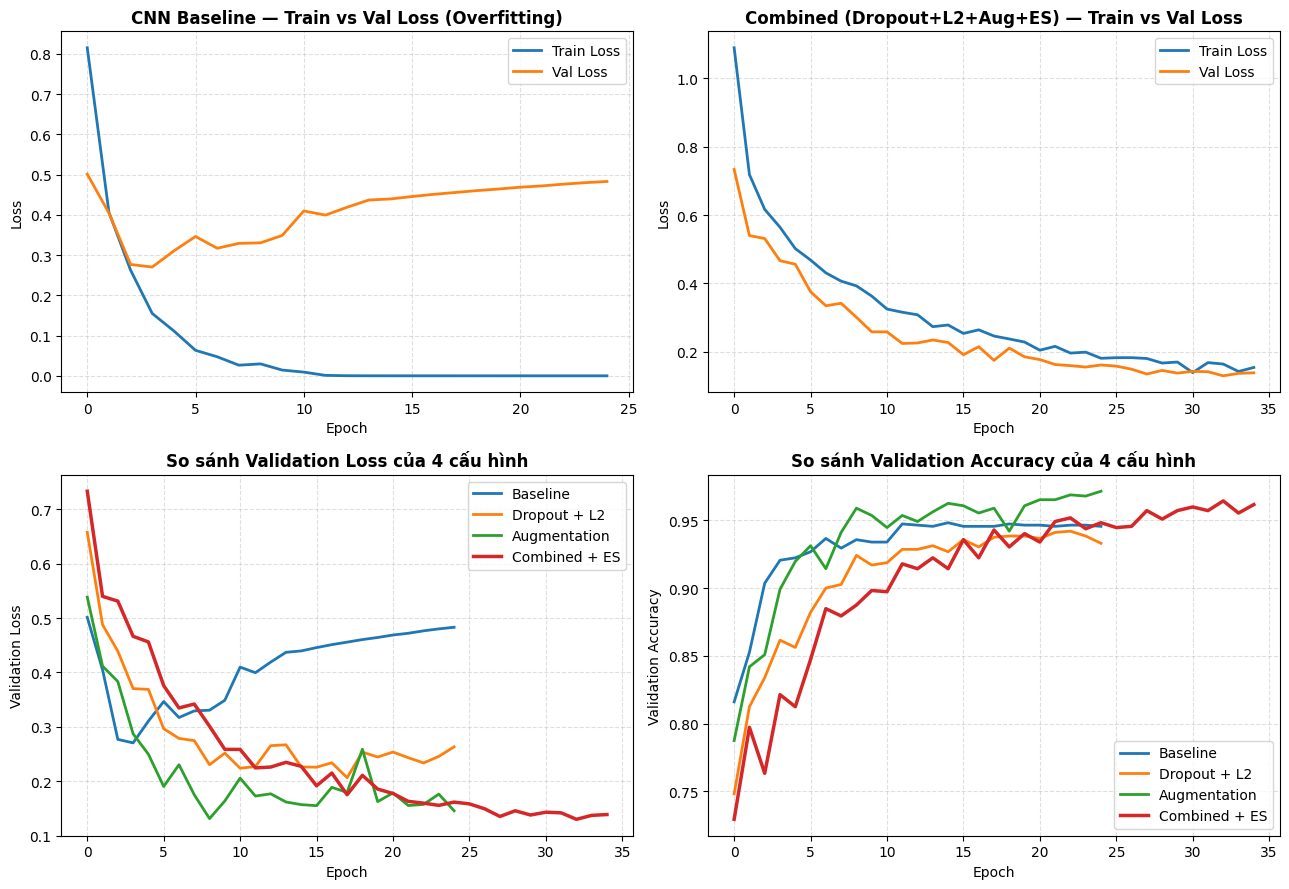

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 9), facecolor="white")

axes[0, 0].plot(history_base["train_loss"], label="Train Loss", linewidth=2)
axes[0, 0].plot(history_base["val_loss"],   label="Val Loss",   linewidth=2)
axes[0, 0].set_title("CNN Baseline — Train vs Val Loss (Overfitting)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(linestyle="--", alpha=0.4)

axes[0, 1].plot(hist_full["train_loss"], label="Train Loss", linewidth=2)
axes[0, 1].plot(hist_full["val_loss"],   label="Val Loss",   linewidth=2)
axes[0, 1].set_title("Combined (Dropout+L2+Aug+ES) — Train vs Val Loss", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(linestyle="--", alpha=0.4)

axes[1, 0].plot(history_base["val_loss"], label="Baseline",      linewidth=2)
axes[1, 0].plot(hist_drop_l2["val_loss"], label="Dropout + L2",  linewidth=2)
axes[1, 0].plot(hist_aug["val_loss"],     label="Augmentation",  linewidth=2)
axes[1, 0].plot(hist_full["val_loss"],    label="Combined + ES", linewidth=2.5)
axes[1, 0].set_title("Validation Loss Across 4 Configurations", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Validation Loss")
axes[1, 0].legend()
axes[1, 0].grid(linestyle="--", alpha=0.4)

axes[1, 1].plot(history_base["val_acc"], label="Baseline",      linewidth=2)
axes[1, 1].plot(hist_drop_l2["val_acc"], label="Dropout + L2",  linewidth=2)
axes[1, 1].plot(hist_aug["val_acc"],     label="Augmentation",  linewidth=2)
axes[1, 1].plot(hist_full["val_acc"],    label="Combined + ES", linewidth=2.5)
axes[1, 1].set_title("Validation Accuracy Across 4 Configurations", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Validation Accuracy")
axes[1, 1].legend()
axes[1, 1].grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("../figures/learning_curves.png", dpi=300)
plt.show()

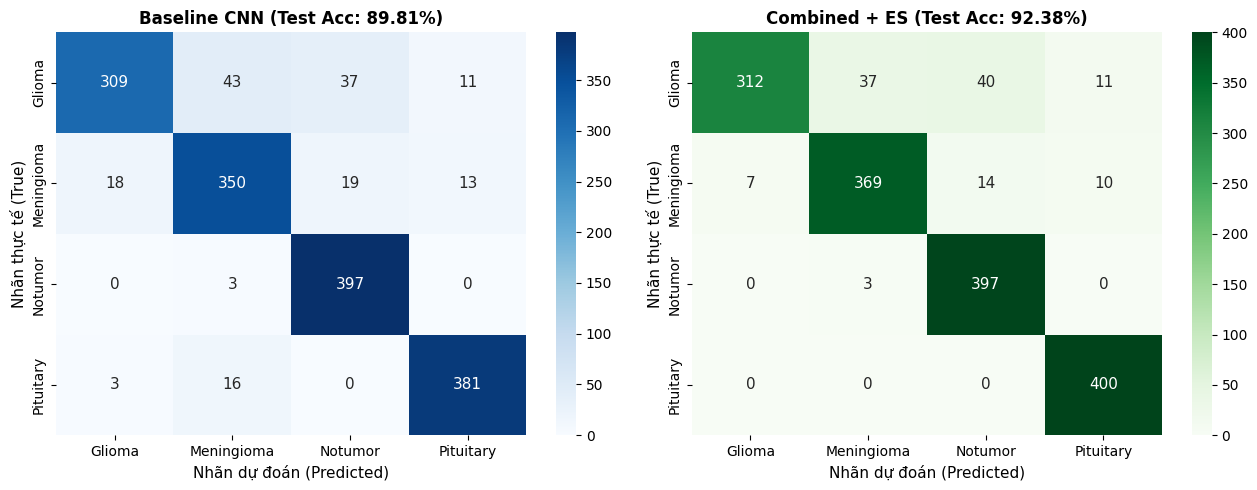

In [15]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_base = confusion_matrix(results["Baseline"]["y_true"],    results["Baseline"]["y_pred"])
cm_full = confusion_matrix(results["Combined+ES"]["y_true"], results["Combined+ES"]["y_pred"])
class_labels = [c.capitalize() for c in classes]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor="white")

sns.heatmap(cm_base, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_labels, yticklabels=class_labels, ax=axes[0], annot_kws={"size": 11})
axes[0].set_title(f"Baseline CNN (Test Acc: {results['Baseline']['test_acc']*100:.2f}%)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted Label", fontsize=11)
axes[0].set_ylabel("True Label", fontsize=11)

sns.heatmap(cm_full, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_labels, yticklabels=class_labels, ax=axes[1], annot_kws={"size": 11})
axes[1].set_title(f"Combined + ES (Test Acc: {results['Combined+ES']['test_acc']*100:.2f}%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Label", fontsize=11)
axes[1].set_ylabel("True Label", fontsize=11)

plt.tight_layout()
plt.savefig("../figures/confusion_matrix.png", dpi=300)
plt.show()

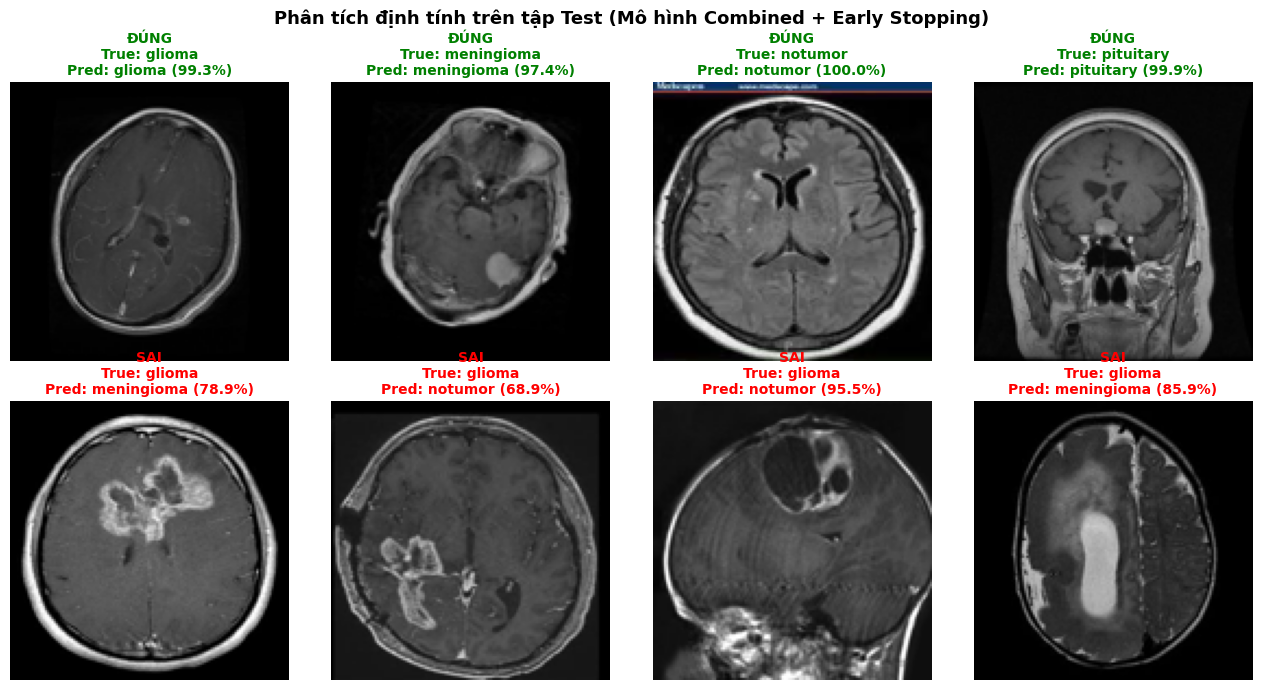

In [16]:
from PIL import Image
import numpy as np

y_true_f  = results["Combined+ES"]["y_true"]
y_pred_f  = results["Combined+ES"]["y_pred"]
y_probs_f = results["Combined+ES"]["y_probs"]

correct_idx = []
for c in range(len(classes)):
    idx_c = np.where((y_true_f == c) & (y_pred_f == c))[0]
    if len(idx_c) > 0:
        correct_idx.append(idx_c[0])

wrong_idx = np.where(y_true_f != y_pred_f)[0][:4]

fig, axes = plt.subplots(2, 4, figsize=(13, 7), facecolor="white")

# Row 1: Correctly classified samples
for col, idx in enumerate(correct_idx):
    img_path, _ = test_dataset.samples[idx]
    img = Image.open(img_path).convert("RGB").resize((128, 128))
    conf = y_probs_f[idx][y_pred_f[idx]] * 100
    axes[0, col].imshow(img)
    axes[0, col].axis("off")
    axes[0, col].set_title(
        f"CORRECT\nTrue: {classes[y_true_f[idx]]}\nPred: {classes[y_pred_f[idx]]} ({conf:.1f}%)",
        fontsize=10, color="green", fontweight="bold"
    )

# Row 2: Misclassified samples
for col, idx in enumerate(wrong_idx):
    img_path, _ = test_dataset.samples[idx]
    img = Image.open(img_path).convert("RGB").resize((128, 128))
    conf = y_probs_f[idx][y_pred_f[idx]] * 100
    axes[1, col].imshow(img)
    axes[1, col].axis("off")
    axes[1, col].set_title(
        f"MISCLASSIFIED\nTrue: {classes[y_true_f[idx]]}\nPred: {classes[y_pred_f[idx]]} ({conf:.1f}%)",
        fontsize=10, color="red", fontweight="bold"
    )

plt.suptitle("Qualitative Error Analysis on Test Set (Combined + Early Stopping)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../figures/qualitative_errors.png", dpi=300)
plt.show()

---
## Section 5: Transfer Learning Extension — Fine-Tuning Pre-trained ResNet18
* Apply **Transfer Learning** using ImageNet-pretrained `ResNet18`, replacing the final classification head with `Dropout(0.3) -> Linear(512, 4)`.
* Run full fine-tuning with Adam (`lr = 1e-4`, `weight_decay = 1e-4`), Data Augmentation, and Early Stopping (`patience = 5`), then compare all 5 configurations on the independent test set.

In [17]:
from torchvision import models

torch.manual_seed(42)

# 1. Load ImageNet-pretrained ResNet18
model_resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# 2. Replace classification head (512 -> 4 classes) with Dropout(0.3)
in_features = model_resnet.fc.in_features
model_resnet.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, len(classes))
)
model_resnet = model_resnet.to(device)

print("Trainable ResNet18 parameters:", sum(p.numel() for p in model_resnet.parameters() if p.requires_grad))

# 3. Full fine-tuning with lr=1e-4 and Early Stopping
model_resnet, hist_resnet = train_model(
    model=model_resnet,
    train_loader=train_loader_aug,
    val_loader=val_loader,
    num_epochs=20,
    lr=1e-4,
    weight_decay=1e-4,
    use_early_stopping=True,
    patience=5
)

Tổng tham số ResNet18: 11178564
Epoch [01/20] Train Loss: 0.3877 | Train Acc: 0.8538 || Val Loss: 0.2000 | Val Acc: 0.9223
Epoch [02/20] Train Loss: 0.1864 | Train Acc: 0.9388 || Val Loss: 0.1448 | Val Acc: 0.9446
Epoch [03/20] Train Loss: 0.1046 | Train Acc: 0.9643 || Val Loss: 0.1030 | Val Acc: 0.9625
Epoch [04/20] Train Loss: 0.0877 | Train Acc: 0.9692 || Val Loss: 0.0711 | Val Acc: 0.9723
Epoch [05/20] Train Loss: 0.0693 | Train Acc: 0.9739 || Val Loss: 0.0694 | Val Acc: 0.9732
Epoch [06/20] Train Loss: 0.0608 | Train Acc: 0.9797 || Val Loss: 0.0613 | Val Acc: 0.9750
Epoch [07/20] Train Loss: 0.0392 | Train Acc: 0.9866 || Val Loss: 0.0466 | Val Acc: 0.9839
Epoch [08/20] Train Loss: 0.0276 | Train Acc: 0.9911 || Val Loss: 0.0568 | Val Acc: 0.9821
Epoch [09/20] Train Loss: 0.0235 | Train Acc: 0.9920 || Val Loss: 0.0576 | Val Acc: 0.9821
Epoch [10/20] Train Loss: 0.0368 | Train Acc: 0.9891 || Val Loss: 0.1026 | Val Acc: 0.9705
Epoch [11/20] Train Loss: 0.0302 | Train Acc: 0.9895 || Va

In [18]:
t_loss, t_acc, t_f1, y_t, y_p, y_pr = evaluate_model(model_resnet, test_loader, criterion, device)
results["ResNet18 (Fine-tune)"] = {
    "test_loss": t_loss, "test_acc": t_acc, "test_f1": t_f1,
    "y_true": y_t, "y_pred": y_p, "y_probs": y_pr
}

print(f"[ResNet18 Fine-tune] Test Loss: {t_loss:.4f} | Test Acc: {t_acc:.4f} | Macro F1: {t_f1:.4f}\n")
print(classification_report(y_t, y_p, target_names=classes, digits=4))

# Summary table across all 5 configurations
print("=" * 68)
print(f"{'Model':<24s} | {'Test Loss':>10s} | {'Test Acc':>10s} | {'Macro F1':>10s}")
print("-" * 68)
for name, r in results.items():
    print(f"{name:<24s} | {r['test_loss']:>10.4f} | {r['test_acc']*100:>9.2f}% | {r['test_f1']:>10.4f}")
print("=" * 68)

[ResNet18 Fine-tune] Test Loss: 0.3289 | Test Acc: 0.9444 | Macro F1: 0.9432

              precision    recall  f1-score   support

      glioma     0.9731    0.8150    0.8871       400
  meningioma     0.8833    0.9650    0.9223       400
     notumor     0.9412    1.0000    0.9697       400
   pituitary     0.9901    0.9975    0.9938       400

    accuracy                         0.9444      1600
   macro avg     0.9469    0.9444    0.9432      1600
weighted avg     0.9469    0.9444    0.9432      1600

Mô hình                  |  Test Loss |   Test Acc |   Macro F1
--------------------------------------------------------------------
Baseline                 |     2.7006 |     89.81% |     0.8965
Dropout+L2               |     1.0215 |     90.50% |     0.9031
Augmentation             |     1.1610 |     92.94% |     0.9280
Combined+ES              |     0.5544 |     92.38% |     0.9219
ResNet18 (Fine-tune)     |     0.3289 |     94.44% |     0.9432


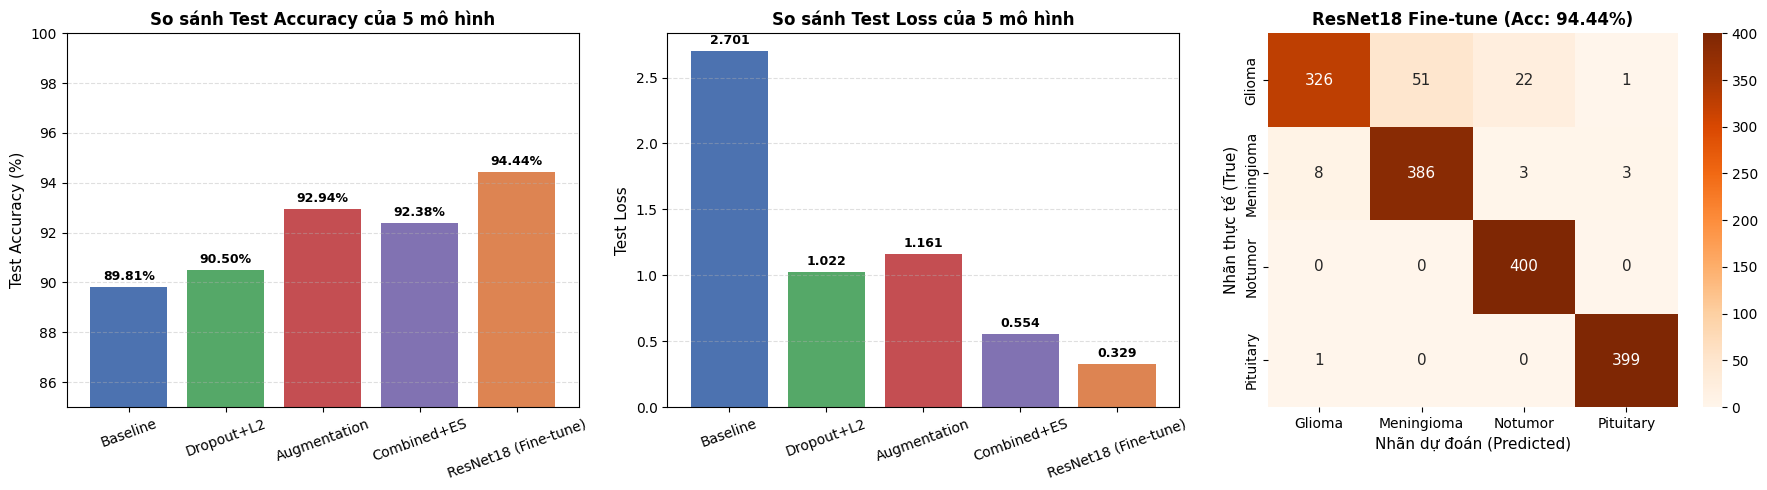

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

model_names = list(results.keys())
test_accs   = [results[m]["test_acc"] * 100 for m in model_names]
test_losses = [results[m]["test_loss"] for m in model_names]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor="white")

# (1) Test Accuracy Comparison (%)
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#DD8452"]
bars1 = axes[0].bar(model_names, test_accs, color=colors)
axes[0].bar_label(bars1, fmt="%.2f%%", padding=3, fontsize=9, fontweight="bold")
axes[0].set_ylim(85, 100)
axes[0].set_ylabel("Test Accuracy (%)", fontsize=11)
axes[0].set_title("Test Accuracy Comparison (5 Models)", fontsize=12, fontweight="bold")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# (2) Test Loss Comparison (lower is better)
bars2 = axes[1].bar(model_names, test_losses, color=colors)
axes[1].bar_label(bars2, fmt="%.3f", padding=3, fontsize=9, fontweight="bold")
axes[1].set_ylabel("Test Loss", fontsize=11)
axes[1].set_title("Test Loss Comparison (5 Models)", fontsize=12, fontweight="bold")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

# (3) 4x4 Confusion Matrix for ResNet18 (Fine-tune)
cm_res = confusion_matrix(results["ResNet18 (Fine-tune)"]["y_true"], results["ResNet18 (Fine-tune)"]["y_pred"])
class_labels = [c.capitalize() for c in classes]
sns.heatmap(cm_res, annot=True, fmt="d", cmap="Oranges",
            xticklabels=class_labels, yticklabels=class_labels, ax=axes[2], annot_kws={"size": 11})
axes[2].set_title(f"ResNet18 Fine-tune (Acc: {results['ResNet18 (Fine-tune)']['test_acc']*100:.2f}%)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Predicted Label", fontsize=11)
axes[2].set_ylabel("True Label", fontsize=11)

plt.tight_layout()
plt.savefig("../figures/model_comparison.png", dpi=300)
plt.show()